# AfroViewz 02: Cleaning, de-duplication and a leak free split

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JBWandera/Capstone/blob/afroviewz/notebooks/02_data_cleaning_and_split.ipynb)

**Workflow stage:** data preparation.

The v1 capstone used the train, valid and test split that came with one Roboflow download. Public pothole datasets are full of repeats: the same photo uploaded to several projects, augmented copies of one photo, and consecutive frames of one drive. When a near copy of a test image sits in the training set, the test score measures memory, not skill.

This notebook:
1. merges the cleaned sources from notebook 01,
2. finds near duplicate images with perceptual hashing, inside and across sources,
3. drops exact repeats and ties near repeats into one group,
4. splits **by group** (80 / 10 / 10 per source), so no group spans two splits,
5. checks the split for leakage and exports it in the layout RF-DETR reads.

The Ugandan Mapillary photos are left out on purpose: they are a holdout, labelled in notebook 04 and never used for training.

## 1. Setup

In [1]:
# Works on Colab and locally. On Colab: mounts Drive, gets the code, installs it.
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.exists("/content/Capstone"):
        subprocess.run(["git", "clone", "-q", "-b", "afroviewz", "https://github.com/JBWandera/Capstone.git", "/content/Capstone"], check=True)
    else:
        subprocess.run(["git", "-C", "/content/Capstone", "pull", "-q"], check=True)
    os.chdir("/content/Capstone")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[data]"], check=True)
    sys.path.insert(0, "/content/Capstone/src")
from afroviewz import paths
print("data root:", paths.data_root())


data root: /home/claude/afz/data


In [2]:
import json
from pathlib import Path
import pandas as pd
from afroviewz.data import build, coco as C, dedup, split

TRAIN_SOURCES = ["stellenbosch", "roboflow_seg", "capstone_v1"]
DATASET = "afroviewz-v1"
OUT = paths.processed_dir(DATASET)  # on Drive: all.coco.json and reports
EXPORT = Path("/content") / DATASET if IN_COLAB else OUT  # image copies for training: local disk on Colab
interim = {name: paths.interim_dir(name) for name in TRAIN_SOURCES}
for name, d in interim.items():
    print(name, C.summary(C.load(d / "coco.json")))


stellenbosch {'images': 5445, 'annotations': 7109, 'images_with_potholes': 2920, 'negative_images': 2525, 'by_source': {'stellenbosch': 5445}}
roboflow_seg {'images': 1342, 'annotations': 2915, 'images_with_potholes': 1340, 'negative_images': 2, 'by_source': {'roboflow_seg': 1342}}
capstone_v1 {'images': 665, 'annotations': 1738, 'images_with_potholes': 665, 'negative_images': 0, 'by_source': {'capstone_v1': 665}}


## 2. How perceptual hashing finds near duplicates

A pHash shrinks an image to 32x32 grey pixels, takes the discrete cosine transform and keeps the sign pattern of the 64 lowest frequencies. Resizing, recompression, small colour shifts and small crops barely change those 64 bits, so two images whose hashes differ in 6 bits or fewer (Hamming distance) are treated as the same scene.

Comparing every pair of 7,000+ images is 25 million comparisons. Instead the 64 bits are cut into 8 bands of 8 bits: two hashes within distance 7 must match exactly on at least one band, so only images sharing a band are compared.

**A check on pixels.** pHash alone over-merges dashcam footage: the car bonnet and the sky fill most of every Stellenbosch frame, so frames of different roads hash alike and chain into clusters of hundreds of images. In a first run, the largest cluster held 713 frames. Every candidate pair is therefore also compared on pixels (mean absolute difference of 64x64 grey thumbnails, 0 to 255): at most 6 for a near duplicate, at most 2 for an exact repeat that gets dropped.

## 3. Build the dataset

**The split is frozen.** The first models were trained on the split published on 13 November. A later rebuild placed about 140 images differently: a group whose images came equally from two sources was assigned to one of them by Python's set order, which changes between runs. The tie is now broken by name, and the published split is stored in `configs/manifests/afroviewz-v1_frozen_splits.csv`. The build reads it, so this notebook always reproduces the dataset the models were trained and scored on; only images it does not list are split by the grouped rule.

In [3]:
FROZEN = paths.CONFIG_DIR / "manifests" / f"{DATASET}_frozen_splits.csv"
report = build.build_from_interim(interim, OUT, dup_distance=6, max_mad=6.0, seed=42, export_root=EXPORT,
                                  frozen_splits=FROZEN)
print(json.dumps(report["dedup"], indent=2))


{
  "phash_max_distance": 6,
  "pixel_max_mad": 6.0,
  "largest_cluster": 86,
  "exact_repeats_dropped": 1560,
  "near_duplicate_clusters": 267,
  "images_in_clusters": 1025,
  "groups_merged_by_near_duplicates": 190
}


## 4. What de-duplication found

In [4]:
allc = C.load(OUT / "all.coco.json")
imgs = pd.DataFrame(allc["images"])
clusters = imgs.groupby("dup_cluster").agg(n=("id", "size"), sources=("source", lambda s: ",".join(sorted(set(s)))))
multi = clusters[clusters.n > 1]
print(f"{len(multi)} near duplicate clusters holding {multi.n.sum()} images")
print("clusters that span more than one source:", (multi.sources.str.contains(",")).sum())
multi.sources.value_counts().head(10)


267 near duplicate clusters holding 1025 images
clusters that span more than one source: 74


sources
stellenbosch                178
capstone_v1,roboflow_seg     74
roboflow_seg                 15
Name: count, dtype: int64

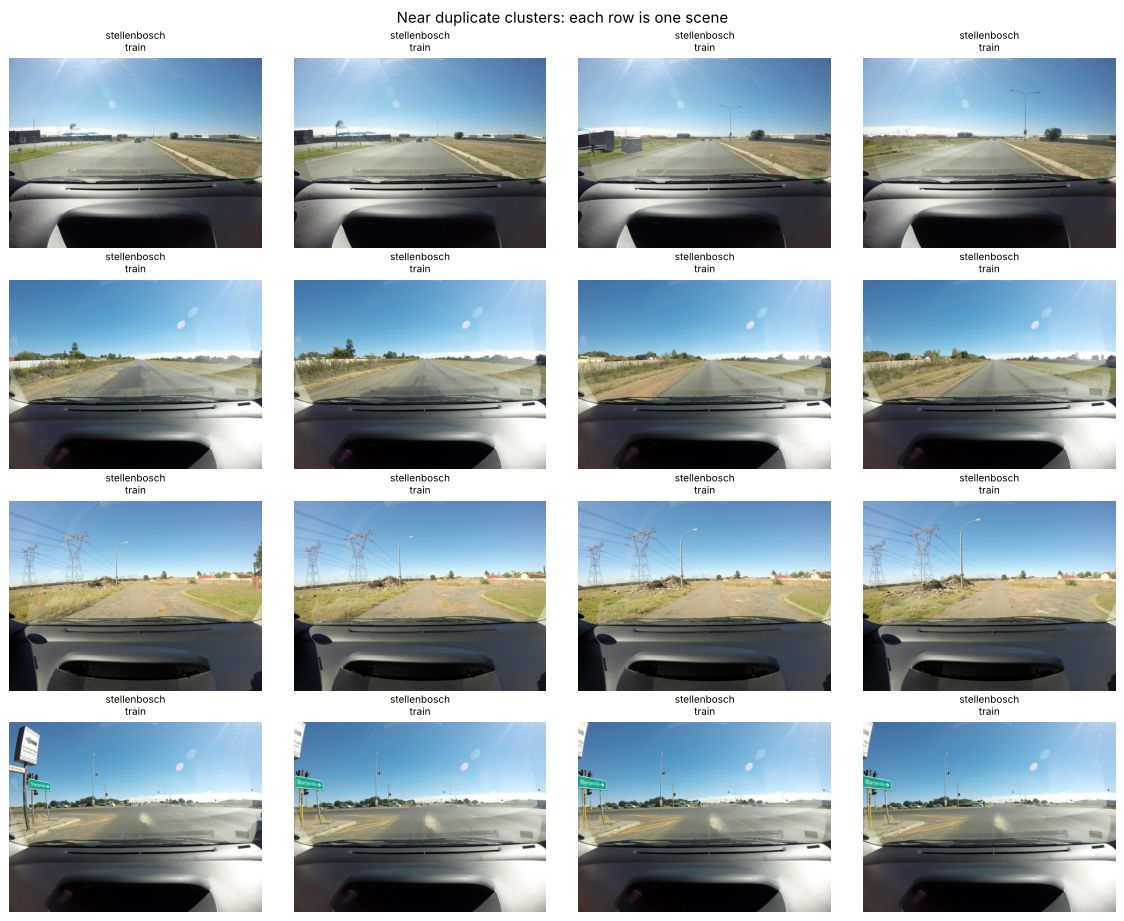

In [5]:
import matplotlib.pyplot as plt
from afroviewz.viz import show_jpeg
from PIL import Image

def show_cluster_examples(k=4, per=4):
    if multi.empty:
        print('No near duplicates found.')
        return
    k = min(k, len(multi))
    big = multi.sort_values("n", ascending=False).head(k).index
    fig, axes = plt.subplots(k, per, figsize=(3.2 * per, 2.6 * k), squeeze=False)
    for r, cid in enumerate(big):
        rows = imgs[imgs.dup_cluster == cid].head(per)
        for c in range(per):
            ax = axes[r, c]
            ax.set_axis_off()
            if c < len(rows):
                im = rows.iloc[c]
                ax.imshow(Image.open(paths.image_path(im.file_name)))
                ax.set_title(f"{im.source}\n{im.split}", fontsize=8)
    plt.suptitle("Near duplicate clusters: each row is one scene")
    plt.tight_layout(); show_jpeg(fig)

show_cluster_examples()


## 5. The split

Each row of a cluster above sits in one split only. The table below shows images and boxes per split and source.

In [6]:
anns = pd.DataFrame(allc["annotations"])
box_counts = anns.groupby("image_id").size()
imgs["boxes"] = imgs.id.map(box_counts).fillna(0).astype(int)
table = imgs.groupby(["split", "source"]).agg(images=("id", "size"), boxes=("boxes", "sum"),
                                              pothole_free=("boxes", lambda b: (b == 0).sum()))
table


images  boxes  pothole_free
split source                                   
test  capstone_v1       36    102             0
      roboflow_seg     111    256             0
      stellenbosch     445    488           237
train capstone_v1      288    828             0
      roboflow_seg     899   1982             1
      stellenbosch    3579   3879          1872
valid capstone_v1       37    110             0
      roboflow_seg     112    242             0
      stellenbosch     385    555           160

In [7]:
problems = split.check_no_leakage(allc, {s: imgs[imgs.split == s].id.tolist() for s in imgs.split.unique()})
assert not problems, problems[:5]
cross = imgs.groupby("dup_cluster").split.nunique()
assert (cross <= 1).all()
print("No group and no near duplicate cluster spans two splits.")


No group and no near duplicate cluster spans two splits.


## 6. Compare with the v1 capstone split

How much of the old v1 test set had a near copy in the old v1 training set? This is the leakage the v1 numbers carried.

In [8]:
v1 = imgs[imgs.source == "capstone_v1"]
old_test = v1[v1.orig_split == "test"]
old_train_clusters = set(v1[v1.orig_split == "train"].dup_cluster)
leaked = old_test.dup_cluster.isin(old_train_clusters)
print(f"v1 test images with a near copy in v1 train: {leaked.sum()} of {len(old_test)} ({leaked.mean():.0%})")


v1 test images with a near copy in v1 train: 0 of 32 (0%)


## 7. Reproducibility check and the training package

The split built here is compared with the manifest committed to the repository (`configs/manifests/afroviewz-v1_splits.csv`). On a fresh run they should match image for image; any difference is listed. Then the RF-DETR folder is zipped to Drive for the training notebooks.

In [9]:
manifest_path = paths.CONFIG_DIR / "manifests" / f"{DATASET}_splits.csv"
mine = build.split_manifest(allc)
if manifest_path.exists():
    ref = pd.read_csv(manifest_path)
    both = ref.merge(mine, on="file_name", how="outer", suffixes=("_ref", "_now"), indicator=True)
    diff = both[(both._merge != "both") | (both.split_ref != both.split_now)]
    print(f"{len(ref)} images in the manifest, {len(mine)} now, {len(diff)} differ")
    display(diff.head(20))
else:
    manifest_path.parent.mkdir(parents=True, exist_ok=True)
    mine.to_csv(manifest_path, index=False)
    print("manifest written:", manifest_path)
zip_path = build.zip_export(EXPORT, paths.data_root() / "processed" / f"{DATASET}.zip", DATASET)
print(zip_path, round(zip_path.stat().st_size / 1e9, 2), "GB")


5892 images in the manifest, 5892 now, 0 differ


,file_name,source_ref,split_ref,group_ref,phash_ref,source_now,split_now,group_now,phash_now,_merge


/home/claude/afz/data/processed/afroviewz-v1.zip 1.85 GB


## Outputs

`processed/afroviewz-v1/` on Drive:
* `afroviewz-v1.zip` (in `processed/`): `train|valid|test/_annotations.coco.json` with the images, ready for RF-DETR
* `all.coco.json` with every image's source, group, near duplicate cluster and split
* `build_report.json`

**Next:** notebook 03, exploratory data analysis.